# Taller 2 — Evaluación, resultados y análisis del agente DQN

**Grupo 4 · Persona 4 · Ambiente:** `LunarLander-v3`

Este notebook evalúa el agente DQN del grupo y analiza sus resultados. Hace cuatro cosas:

1. Repite el entrenamiento de la Persona 3 con el mismo código y las mismas semillas (42, 123 y 2026), guardando una copia de los pesos cada 25 episodios (un *punto de control*).
2. Analiza cómo cambian la recompensa y la duración de los episodios durante el entrenamiento.
3. Mide qué tan estable es el modelo que se guarda, evaluando cada punto de control sin exploración.
4. Evalúa los modelos con 100 semillas nuevas y revisa cómo termina cada episodio.

**Cómo ejecutarlo.** Basta con ejecutar todas las celdas. Los entrenamientos ya están guardados en `resultados/replica/` y `modelos/replica/`, así que tarda menos de un minuto. Con `REPETIR_ENTRENAMIENTO = True` se vuelve a entrenar (unos 15 minutos en un portátil; en Colab bastante más).

**Importante.** Los resultados guardados se obtuvieron en un computador con procesador ARM. Si se vuelve a entrenar en otra máquina, los números cambian aunque las semillas sean las mismas (sección 8).

In [1]:
# En Colab: traer el repositorio (modelos y resultados guardados) e instalar el ambiente.
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('resultados'):
    !git clone -q https://github.com/mafrvargas-jpg/taller-2-dqn-gymnasium.git
    %cd taller-2-dqn-gymnasium
    %pip -q install "gymnasium[box2d]"

In [2]:
import copy, random, time
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from torch import nn, optim

torch.set_num_threads(1)   # la red es pequeña: un solo hilo es más rápido y da siempre el mismo resultado

AMBIENTE = 'LunarLander-v3'
SEMILLAS_ENTRENAMIENTO = [42, 123, 2026]          # las mismas de la Persona 3
SEMILLAS_VALIDACION = list(range(10000, 10100))   # las que usó la Persona 3 para comparar modelos
SEMILLAS_PRUEBA = list(range(20000, 20100))       # nuevas: no se usan para elegir nada
CADA = 25                                         # se guarda un punto de control cada 25 episodios
UMBRAL = 200                                      # puntaje con el que Gymnasium considera resuelto el episodio

REPETIR_ENTRENAMIENTO = False   # True vuelve a entrenar aunque ya existan los resultados guardados

DIR_RESULTADOS = Path('resultados/replica')
DIR_MODELOS = Path('modelos/replica')
DIR_FIGURAS = Path('figuras')
for carpeta in (DIR_RESULTADOS, DIR_MODELOS, DIR_FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Estilo de las gráficas
AZUL, NARANJA, VERDE, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
COLOR_SEMILLA = {42: AZUL, 123: NARANJA, 2026: VERDE}
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.edgecolor': '#c9c8c2', 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e9e8e4', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'text.color': '#0b0b0b', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2, 'lines.solid_capstyle': 'round',
})

def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / nombre, dpi=160, bbox_inches='tight')

print('torch', torch.__version__, '| gymnasium', gym.__version__, '| numpy', np.__version__)

torch 2.11.0 | gymnasium 1.3.0 | numpy 2.1.3


## 1. El agente y el entrenamiento

Se usa la red de la Persona 2 (8 → 128 → 128 → 4 con ReLU) y el ciclo de entrenamiento de la Persona 3 con sus hiperparámetros: tasa de aprendizaje 0.001, γ = 0.99, lotes de 64, buffer de 100.000 experiencias, ε de 1.0 a 0.01 multiplicando por 0.995 al final de cada episodio, red objetivo copiada cada 10 episodios y pérdida MSE.

El único cambio es que cada 25 episodios se guarda una copia de los pesos. Eso no altera el entrenamiento: solo permite revisar después cómo iba el agente en cada momento.

In [3]:
def sembrar(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)

class DQN(nn.Module):
    """Red de la Persona 2: 8 -> 128 -> 128 -> 4 con ReLU."""
    def __init__(self, n_estado=8, n_acciones=4):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(n_estado, 128), nn.ReLU(),
                                     nn.Linear(128, 128), nn.ReLU(),
                                     nn.Linear(128, n_acciones))
    def forward(self, x):
        return self.network(x)

class ReplayBuffer:
    def __init__(self, capacidad=100000):
        self.buffer = deque(maxlen=capacidad)
    def push(self, s, a, r, ns, terminado):
        self.buffer.append((np.asarray(s, dtype=np.float32).copy(), int(a), float(r),
                            np.asarray(ns, dtype=np.float32).copy(), float(terminado)))
    def sample(self, n):
        s, a, r, ns, d = zip(*random.sample(self.buffer, n))
        return (np.asarray(s, dtype=np.float32), np.asarray(a, dtype=np.int64),
                np.asarray(r, dtype=np.float32), np.asarray(ns, dtype=np.float32),
                np.asarray(d, dtype=np.float32))
    def __len__(self):
        return len(self.buffer)

In [4]:
def entrenar_con_puntos_de_control(semilla, episodios=1000, lr=0.001, lote=64, gamma=0.99,
                                   eps_decay=0.995, eps_min=0.01, copiar_objetivo=10,
                                   capacidad=100000, cada=CADA):
    """Entrenamiento de la Persona 3 sin cambios. Lo único nuevo es que cada `cada` episodios
    se guarda una copia de los pesos, para poder evaluar después cómo iba el agente en ese momento."""
    sembrar(semilla)
    env = gym.make(AMBIENTE)
    env.action_space.seed(semilla)
    red = DQN()
    objetivo = DQN()
    objetivo.load_state_dict(red.state_dict()); objetivo.eval()
    optimizador = optim.Adam(red.parameters(), lr=lr)
    perdida_fn = nn.MSELoss()
    memoria = ReplayBuffer(capacidad)
    epsilon = 1.0
    filas, copias = [], {}
    for ep in range(1, episodios + 1):
        estado, _ = env.reset(seed=semilla + ep)
        total, pasos, perdidas = 0.0, 0, []
        terminado = truncado = False
        while not (terminado or truncado):
            # epsilon-greedy
            if random.random() < epsilon:
                accion = env.action_space.sample()
            else:
                with torch.no_grad():
                    accion = int(red(torch.as_tensor(estado, dtype=torch.float32).unsqueeze(0)).argmax(dim=1).item())
            siguiente, recompensa, terminado, truncado, _ = env.step(accion)
            # solo `terminado` corta el valor futuro; llegar al límite de pasos no es un estado terminal
            memoria.push(estado, accion, recompensa, siguiente, terminado)
            if len(memoria) >= lote:
                s, a, r, ns, d = memoria.sample(lote)
                s = torch.as_tensor(s); a = torch.as_tensor(a).unsqueeze(1)
                r = torch.as_tensor(r).unsqueeze(1); ns = torch.as_tensor(ns); d = torch.as_tensor(d).unsqueeze(1)
                q = red(s).gather(1, a)
                with torch.no_grad():
                    y = r + gamma * objetivo(ns).max(dim=1, keepdim=True).values * (1 - d)   # Bellman
                perdida = perdida_fn(q, y)
                optimizador.zero_grad(); perdida.backward(); optimizador.step()
                perdidas.append(float(perdida.item()))
            estado = siguiente
            total += float(recompensa); pasos += 1
        epsilon = max(eps_min, epsilon * eps_decay)
        if ep % copiar_objetivo == 0:
            objetivo.load_state_dict(red.state_dict())
        filas.append({'semilla': semilla, 'episodio': ep, 'recompensa': total, 'pasos': pasos, 'epsilon': epsilon,
                      'perdida_media': float(np.mean(perdidas)) if perdidas else np.nan})
        if ep % cada == 0:
            copias[ep] = copy.deepcopy(red.state_dict())
    env.close()
    return pd.DataFrame(filas), copias

## 2. Cómo se evalúa

- **Sin exploración.** El agente siempre elige la acción con mayor valor Q.
- **Un episodio por semilla.** Así todos los modelos enfrentan exactamente las mismas condiciones iniciales.
- **Dos grupos de semillas.** Las de *validación* (10000 a 10099, las mismas de la Persona 3) sirven para comparar puntos de control. Las de *prueba* (20000 a 20099) solo se usan para el resultado final, de modo que no influyen en la elección del modelo.
- **Se registra cómo termina cada episodio.** LunarLander entrega +100 en el último paso cuando la nave queda quieta y −100 cuando se estrella o se sale de la pantalla. Si no pasa ninguna de las dos cosas, el episodio se corta a los 1.000 pasos. Eso da tres desenlaces: *aterriza y queda en reposo*, *se estrella o sale de la pantalla* y *llega al límite de 1.000 pasos*.

Superar 200 puntos no es lo mismo que aterrizar. Por eso se reportan las dos cosas por separado.

In [5]:
NOMBRE_DESENLACE = {'reposo': 'Aterriza y queda en reposo',
                    'limite_tiempo': 'Llega al límite de 1.000 pasos',
                    'choque_o_fuera': 'Se estrella o sale de la pantalla'}

# Medio ancho de la plataforma en las unidades de la observación (se lee del propio ambiente)
from gymnasium.envs.box2d import lunar_lander as _ll
_env = gym.make(AMBIENTE); _env.reset(seed=0)
MEDIO_ANCHO_PLATAFORMA = (_env.unwrapped.helipad_x2 - _env.unwrapped.helipad_x1) / (_ll.VIEWPORT_W / _ll.SCALE)
LIMITE_PASOS = _env.spec.max_episode_steps
_env.close()
print('Límite de pasos por episodio:', LIMITE_PASOS, '| la plataforma va de x =', -MEDIO_ANCHO_PLATAFORMA, 'a', MEDIO_ANCHO_PLATAFORMA)

def cargar(ruta):
    modelo = DQN()
    modelo.load_state_dict(torch.load(ruta, map_location='cpu'))
    modelo.eval()
    return modelo

def evaluar(modelo, semillas):
    """Un episodio por semilla. Con un modelo se elige siempre la acción de mayor Q (sin exploración).
    Con modelo=None se juega al azar, como punto de comparación."""
    env = gym.make(AMBIENTE)
    filas = []
    for semilla in semillas:
        estado, _ = env.reset(seed=int(semilla))
        env.action_space.seed(int(semilla))
        vx_inicial = float(estado[2])
        terminado = truncado = False
        total, pasos, usos = 0.0, 0, [0, 0, 0, 0]
        while not (terminado or truncado):
            if modelo is None:
                accion = int(env.action_space.sample())
            else:
                with torch.no_grad():
                    accion = int(modelo(torch.as_tensor(estado, dtype=torch.float32).unsqueeze(0)).argmax(dim=1).item())
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            total += float(recompensa); pasos += 1; usos[accion] += 1
        # El ambiente cierra con +100 si la nave queda quieta y con -100 si se estrella o se sale
        if terminado:
            desenlace = 'reposo' if recompensa == 100 else 'choque_o_fuera'
        else:
            desenlace = 'limite_tiempo'
        patas = int(estado[6] + estado[7])
        filas.append({'semilla_evaluacion': int(semilla), 'recompensa': total, 'pasos': pasos, 'desenlace': desenlace,
                      'vx_inicial': vx_inicial, 'x_final': float(estado[0]), 'patas_en_suelo': patas,
                      # detalles de cada desenlace
                      'en_plataforma': bool(desenlace == 'reposo' and abs(estado[0]) <= MEDIO_ANCHO_PLATAFORMA),
                      'flotando': bool(desenlace == 'limite_tiempo' and patas == 0),
                      'fuera_de_pantalla': bool(desenlace == 'choque_o_fuera' and abs(estado[0]) >= 1.0),
                      'uso_nada': usos[0] / pasos, 'uso_motor_izq': usos[1] / pasos,
                      'uso_motor_principal': usos[2] / pasos, 'uso_motor_der': usos[3] / pasos})
    env.close()
    return pd.DataFrame(filas)

def intervalo_95(valores, repeticiones=5000, semilla=0):
    """Intervalo de confianza del 95 % para la media, por bootstrap."""
    rng = np.random.default_rng(semilla)
    valores = np.asarray(valores, dtype=float)
    medias = valores[rng.integers(0, len(valores), size=(repeticiones, len(valores)))].mean(axis=1)
    return np.percentile(medias, [2.5, 97.5])

def resumir(df):
    r = df.recompensa
    bajo, alto = intervalo_95(r)
    return {'episodios': len(df), 'media': r.mean(), 'desviacion': r.std(ddof=0), 'ic95_inf': bajo, 'ic95_sup': alto,
            'mediana': r.median(), 'minimo': r.min(), 'maximo': r.max(), 'ge_200': int((r >= UMBRAL).sum()),
            'reposo': int((df.desenlace == 'reposo').sum()),
            'limite_tiempo': int((df.desenlace == 'limite_tiempo').sum()),
            'choque_o_fuera': int((df.desenlace == 'choque_o_fuera').sum()),
            'en_plataforma': int(df.en_plataforma.sum()), 'flotando': int(df.flotando.sum()),
            'fuera_de_pantalla': int(df.fuera_de_pantalla.sum()), 'pasos_medios': df.pasos.mean()}

Límite de pasos por episodio: 1000 | la plataforma va de x = -0.2 a 0.2


## 3. Réplica del entrenamiento

Para cada semilla se entrena durante 1.000 episodios y se evalúan los 40 puntos de control con las semillas de validación. Se guardan dos modelos por semilla: el del episodio 1.000 (el que guarda el procedimiento original) y el del punto de control con mejor media.

In [6]:
historiales, controles = {}, {}
for semilla in SEMILLAS_ENTRENAMIENTO:
    f_hist = DIR_RESULTADOS / f'historial_seed{semilla}.csv'
    f_ctrl = DIR_RESULTADOS / f'puntos_de_control_seed{semilla}.csv'
    if REPETIR_ENTRENAMIENTO or not (f_hist.exists() and f_ctrl.exists()):
        inicio = time.time()
        historial, copias = entrenar_con_puntos_de_control(semilla)
        filas = []
        for ep, pesos in copias.items():
            modelo = DQN(); modelo.load_state_dict(pesos); modelo.eval()
            fila = resumir(evaluar(modelo, SEMILLAS_VALIDACION))
            fila.update({'semilla': semilla, 'episodio': ep})
            filas.append(fila)
        control = pd.DataFrame(filas)
        mejor_ep = int(control.loc[control.media.idxmax(), 'episodio'])
        torch.save(copias[1000], DIR_MODELOS / f'seed{semilla}_ep1000.pth')
        torch.save(copias[mejor_ep], DIR_MODELOS / f'seed{semilla}_mejor.pth')
        historial.to_csv(f_hist, index=False); control.to_csv(f_ctrl, index=False)
        print(f'Semilla {semilla}: entrenada y validada en {time.time() - inicio:.0f} s')
    historiales[semilla] = pd.read_csv(f_hist)
    controles[semilla] = pd.read_csv(f_ctrl)
    print(f'Semilla {semilla}: {len(historiales[semilla])} episodios, {len(controles[semilla])} puntos de control')

Semilla 42: 1000 episodios, 40 puntos de control
Semilla 123: 1000 episodios, 40 puntos de control
Semilla 2026: 1000 episodios, 40 puntos de control


## 4. Resultados del entrenamiento

In [7]:
filas = []
for semilla, h in historiales.items():
    r = h.recompensa
    movil = r.rolling(100).mean()
    filas.append({'semilla': semilla,
                  'pasos_totales': int(h.pasos.sum()),
                  'media_ep_1_100': r.iloc[:100].mean(),
                  'media_ep_901_1000': r.iloc[-100:].mean(),
                  'mejor_episodio': r.max(),
                  'peor_episodio': r.min(),
                  'primer_ep_media100_ge_200': int(h.episodio[movil >= UMBRAL].iloc[0]) if (movil >= UMBRAL).any() else None,
                  'episodios_al_limite': int((h.pasos == LIMITE_PASOS).sum())})
tabla_entrenamiento = pd.DataFrame(filas).set_index('semilla')
tabla_entrenamiento.to_csv(DIR_RESULTADOS / 'resumen_entrenamiento.csv')
display(tabla_entrenamiento.round(1))

# Evolución por bloques de 100 episodios (promedio de las tres semillas)
todo = pd.concat(historiales.values())
todo['bloque'] = ((todo.episodio - 1) // 100) * 100 + 100
bloques = todo.groupby('bloque').agg(recompensa_media=('recompensa', 'mean'), pasos_medios=('pasos', 'mean'),
                                     episodios_al_limite=('pasos', lambda p: (p == LIMITE_PASOS).mean() * 100))
bloques.index.name = 'hasta_episodio'
display(bloques.round(1))

,pasos_totales,media_ep_1_100,media_ep_901_1000,mejor_episodio,peor_episodio,primer_ep_media100_ge_200,episodios_al_limite
semilla,,,,,,,
42,450573,-121.8,141.4,308.9,-460.8,NaN,223
123,484185,-131.7,175.9,311.0,-537.8,627.0,261
2026,432380,-108.7,216.4,322.1,-386.6,713.0,181


,recompensa_media,pasos_medios,episodios_al_limite
hasta_episodio,,,
100,-120.7,112.3,0.3
200,-55.2,355.3,16.3
300,-33.6,870.9,74.3
400,7.5,842.3,67.7
500,61.1,598.6,33.7
600,156.7,455.5,8.0
700,174.0,357.2,4.0
800,142.6,308.0,4.0
900,151.8,305.7,5.0


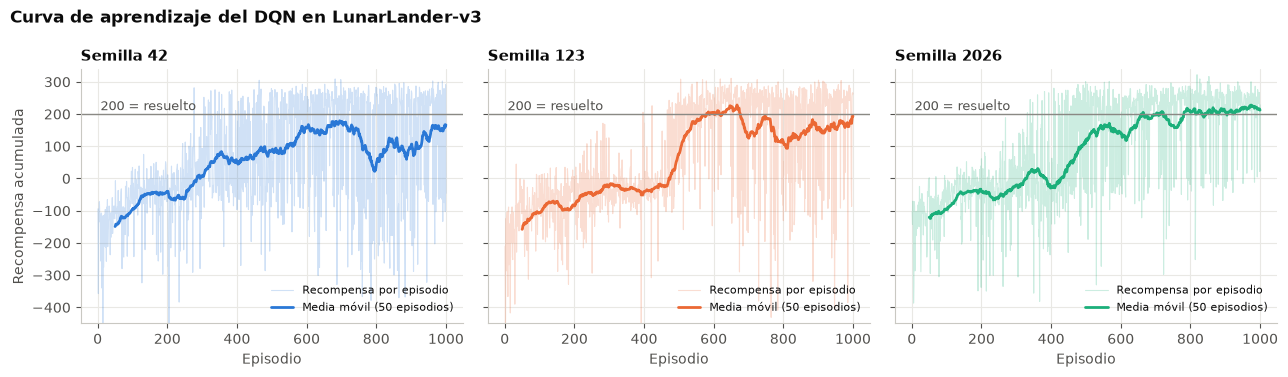

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for eje, (semilla, h) in zip(ejes, historiales.items()):
    color = COLOR_SEMILLA[semilla]
    eje.plot(h.episodio, h.recompensa, color=color, alpha=0.22, linewidth=0.8, label='Recompensa por episodio')
    eje.plot(h.episodio, h.recompensa.rolling(50).mean(), color=color, label='Media móvil (50 episodios)')
    eje.axhline(UMBRAL, color=GRIS, linewidth=1)
    eje.text(8, UMBRAL + 12, '200 = resuelto', color='#52514e', fontsize=9)
    eje.set_title(f'Semilla {semilla}')
    eje.set_xlabel('Episodio')
    eje.set_ylim(-450, 340)
    eje.legend(loc='lower right', fontsize=8)
ejes[0].set_ylabel('Recompensa acumulada')
fig.suptitle('Curva de aprendizaje del DQN en LunarLander-v3', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar(fig, 'curvas_aprendizaje.png')
plt.show()

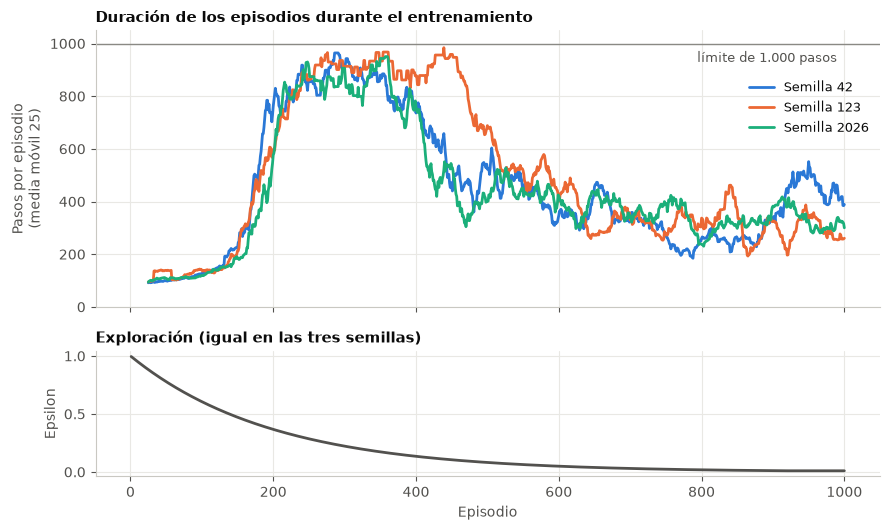

Epsilon llega a 0.01 en el episodio 919


In [9]:
fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, height_ratios=[2.2, 1])
for semilla, h in historiales.items():
    arriba.plot(h.episodio, h.pasos.rolling(25).mean(), color=COLOR_SEMILLA[semilla], label=f'Semilla {semilla}')
arriba.axhline(LIMITE_PASOS, color=GRIS, linewidth=1)
arriba.text(990, LIMITE_PASOS - 70, 'límite de 1.000 pasos', color='#52514e', fontsize=9, ha='right')
arriba.set_ylabel('Pasos por episodio\n(media móvil 25)')
arriba.set_ylim(0, 1050)
arriba.set_title('Duración de los episodios durante el entrenamiento')
arriba.legend(loc='upper right', bbox_to_anchor=(1, 0.86), fontsize=9)
h = historiales[SEMILLAS_ENTRENAMIENTO[0]]
abajo.plot(h.episodio, h.epsilon, color='#52514e')
abajo.set_ylabel('Epsilon')
abajo.set_xlabel('Episodio')
abajo.set_title('Exploración (igual en las tres semillas)')
fig.tight_layout()
guardar(fig, 'duracion_episodios.png')
plt.show()
print('Epsilon llega a 0.01 en el episodio', int(h.episodio[h.epsilon <= 0.01].iloc[0]))

**Lectura.** El aprendizaje pasa por cuatro etapas, que se ven igual en las tres semillas:

1. **Episodios 1 a 100: se estrella.** Con ε entre 1.0 y 0.61 el agente casi solo explora. La recompensa media es −120.7 y los episodios duran 112 pasos en promedio.
2. **Episodios 201 a 400: aprende a no caer, pero no a aterrizar.** El 74 % de los episodios (201–300) y el 68 % (301–400) llegan al límite de 1.000 pasos. La recompensa media sube a −33.6 y 7.5: el agente evita el −100, pero se queda gastando motor.
3. **Episodios 401 a 700: aprende a aterrizar.** La recompensa media sube a 61.1, 156.7 y 174.0, y los episodios se acortan a unos 357 pasos.
4. **Episodios 701 a 1.000: se estanca.** La media por bloque queda en 142.6, 151.8 y 177.9. Solo la semilla 2026 termina por encima de 200 (216.4 en los últimos 100 episodios); la semilla 42 nunca alcanza una media móvil de 200.

ε llega a su mínimo de 0.01 en el episodio 919, así que el agente explora por encima del mínimo durante el 92 % del entrenamiento.

## 5. ¿Qué tan estable es el modelo que se guarda?

La curva de entrenamiento promedia episodios jugados por redes distintas, porque los pesos cambian en cada paso. Para saber qué tan bueno es un modelo concreto hay que congelarlo y evaluarlo. Aquí se evalúa cada punto de control con 100 episodios (semillas de validación).

In [10]:
filas = []
for semilla, c in controles.items():
    final = c[c.episodio >= 800]
    mejor = c.loc[c.media.idxmax()]
    ultimo = c.iloc[-1]
    filas.append({'semilla': semilla,
                  'ultimo_ep_1000': ultimo.media, 'ultimo_ge_200': int(ultimo.ge_200),
                  'mejor_punto_ep': int(mejor.episodio), 'mejor_media': mejor.media, 'mejor_ge_200': int(mejor.ge_200),
                  'min_ep_800_1000': final.media.min(), 'max_ep_800_1000': final.media.max(),
                  'mayor_salto_entre_vecinos': final.media.diff().abs().max(),
                  'puntos_con_media_ge_200': int((c.media >= UMBRAL).sum())})
tabla_control = pd.DataFrame(filas).set_index('semilla')
tabla_control.to_csv(DIR_RESULTADOS / 'resumen_puntos_de_control.csv')
display(tabla_control.round(1))

,ultimo_ep_1000,ultimo_ge_200,mejor_punto_ep,mejor_media,mejor_ge_200,min_ep_800_1000,max_ep_800_1000,mayor_salto_entre_vecinos,puntos_con_media_ge_200
semilla,,,,,,,,,
42,107.1,49,600,159.2,63,-59.1,125.3,184.3,0
123,116.6,62,725,248.5,90,1.7,214.2,187.7,3
2026,99.3,47,975,228.1,77,83.1,228.1,142.0,3


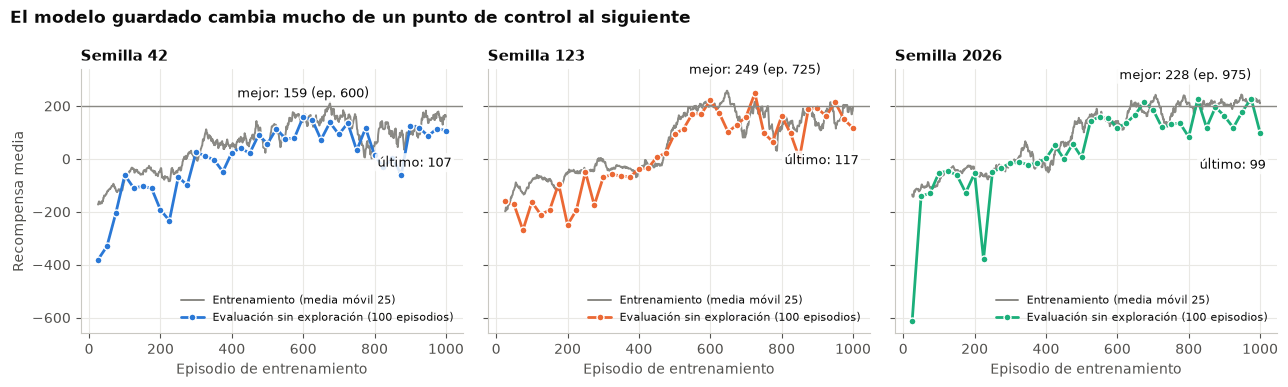

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for eje, semilla in zip(ejes, SEMILLAS_ENTRENAMIENTO):
    h, c = historiales[semilla], controles[semilla]
    eje.plot(h.episodio, h.recompensa.rolling(25).mean(), color=GRIS, linewidth=1.4, label='Entrenamiento (media móvil 25)')
    eje.plot(c.episodio, c.media, color=COLOR_SEMILLA[semilla], marker='o', markersize=5,
             markeredgecolor='white', markeredgewidth=1, label='Evaluación sin exploración (100 episodios)')
    eje.axhline(UMBRAL, color=GRIS, linewidth=1)
    mejor, ultimo = c.loc[c.media.idxmax()], c.iloc[-1]
    caja = dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.85)
    eje.annotate(f'mejor: {mejor.media:.0f} (ep. {int(mejor.episodio)})', (mejor.episodio, mejor.media),
                 xytext=(0, 14), textcoords='offset points', fontsize=9,
                 ha='right' if mejor.episodio > 850 else 'center', color='#0b0b0b', bbox=caja)
    eje.annotate(f'último: {ultimo.media:.0f}', (ultimo.episodio, ultimo.media),
                 xytext=(4, -26), textcoords='offset points', fontsize=9, ha='right', color='#0b0b0b', bbox=caja)
    eje.set_title(f'Semilla {semilla}')
    eje.set_xlabel('Episodio de entrenamiento')
    eje.set_ylim(-660, 340)
    eje.legend(loc='lower right', fontsize=8)
ejes[0].set_ylabel('Recompensa media')
fig.suptitle('El modelo guardado cambia mucho de un punto de control al siguiente', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar(fig, 'estabilidad_puntos_de_control.png')
plt.show()

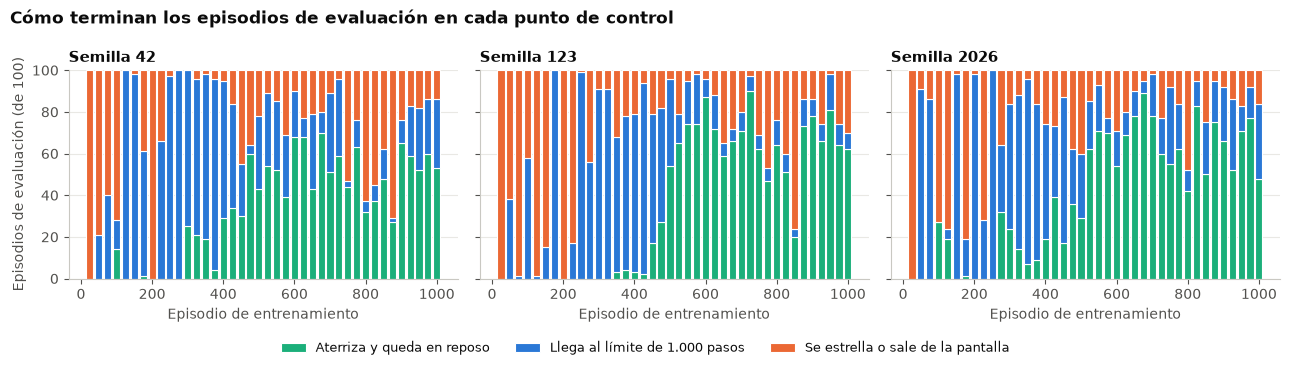

In [12]:
orden = ['reposo', 'limite_tiempo', 'choque_o_fuera']
colores = {'reposo': VERDE, 'limite_tiempo': AZUL, 'choque_o_fuera': NARANJA}
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for eje, semilla in zip(ejes, SEMILLAS_ENTRENAMIENTO):
    c = controles[semilla]
    base = np.zeros(len(c))
    for clave in orden:
        eje.bar(c.episodio, c[clave], bottom=base, width=CADA - 5, color=colores[clave],
                edgecolor='white', linewidth=0.8, label=NOMBRE_DESENLACE[clave])
        base += c[clave].to_numpy()
    eje.set_title(f'Semilla {semilla}')
    eje.set_xlabel('Episodio de entrenamiento')
    eje.grid(axis='x', visible=False)
ejes[0].set_ylabel('Episodios de evaluación (de 100)')
manijas, nombres = ejes[0].get_legend_handles_labels()
fig.legend(manijas, nombres, loc='lower center', ncol=3, fontsize=9)
fig.suptitle('Cómo terminan los episodios de evaluación en cada punto de control', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=[0, 0.07, 1, 1])
guardar(fig, 'desenlaces_por_punto_de_control.png')
plt.show()

**Lectura.**

- **El modelo del episodio 1.000 no es el mejor en ninguna semilla.** Saca 107.1, 116.6 y 99.3, mientras que el mejor punto de control de cada semilla saca 159.2 (episodio 600), 248.5 (episodio 725) y 228.1 (episodio 975).
- **El desempeño salta de un punto de control al siguiente.** En los últimos 200 episodios la media de evaluación va de −59.1 a 125.3 (semilla 42), de 1.7 a 214.2 (semilla 123) y de 83.1 a 228.1 (semilla 2026). El mayor salto entre dos puntos vecinos, separados solo por 25 episodios, es de 184.3, 187.7 y 142.0 puntos.
- **Pocos puntos de control resuelven el ambiente.** De 40 por semilla, superan 200 de media 0, 3 y 3.
- **La curva de entrenamiento no avisa.** En la semilla 2026 la media móvil de entrenamiento al final es 210.6, pero el modelo de ese mismo momento saca 99.3 al evaluarlo.
- **El tipo de fallo también cambia.** En la semilla 123, el punto del episodio 850 se estrella o se sale en 76 de 100 episodios; 25 episodios después aterriza en 73.

La segunda figura muestra el mismo orden de aprendizaje de la sección 4: primero casi todos los episodios terminan en choque, luego el agente se queda en el aire hasta el límite de pasos y solo después empieza a aterrizar.

## 6. Evaluación con semillas nuevas

Se evalúan siete políticas con las 100 semillas de prueba: una política al azar como referencia, el modelo del episodio 1.000 de cada semilla y el mejor punto de control de cada semilla.

In [13]:
evaluaciones = {'Política al azar': evaluar(None, SEMILLAS_PRUEBA)}
for semilla in SEMILLAS_ENTRENAMIENTO:
    mejor_ep = int(controles[semilla].loc[controles[semilla].media.idxmax(), 'episodio'])
    evaluaciones[f'Semilla {semilla} · episodio 1.000'] = evaluar(cargar(DIR_MODELOS / f'seed{semilla}_ep1000.pth'), SEMILLAS_PRUEBA)
    evaluaciones[f'Semilla {semilla} · mejor punto (ep. {mejor_ep})'] = evaluar(cargar(DIR_MODELOS / f'seed{semilla}_mejor.pth'), SEMILLAS_PRUEBA)

tabla_prueba = pd.DataFrame({nombre: resumir(df) for nombre, df in evaluaciones.items()}).T
tabla_prueba.index.name = 'modelo'
tabla_prueba.to_csv(DIR_RESULTADOS / 'evaluacion_semillas_nuevas.csv')
pd.concat([df.assign(modelo=nombre) for nombre, df in evaluaciones.items()]).to_csv(
    DIR_RESULTADOS / 'evaluacion_semillas_nuevas_por_episodio.csv', index=False)
display(tabla_prueba.astype(float).round(1))

,episodios,media,desviacion,ic95_inf,ic95_sup,mediana,minimo,maximo,ge_200,reposo,limite_tiempo,choque_o_fuera,en_plataforma,flotando,fuera_de_pantalla,pasos_medios
modelo,,,,,,,,,,,,,,,,
Política al azar,100.0,-185.5,112.0,-207.8,-164.5,-148.0,-527.9,30.5,0.0,0.0,1.0,99.0,0.0,0.0,8.0,98.6
Semilla 42 · episodio 1.000,100.0,130.0,162.9,97.1,161.7,223.0,-257.0,306.6,57.0,60.0,33.0,7.0,54.0,32.0,2.0,518.5
Semilla 42 · mejor punto (ep. 600),100.0,160.1,121.6,135.2,183.1,220.2,-242.0,288.8,58.0,71.0,21.0,8.0,63.0,15.0,5.0,517.9
Semilla 123 · episodio 1.000,100.0,90.5,246.4,42.6,137.5,244.6,-703.8,303.3,60.0,60.0,6.0,34.0,58.0,1.0,3.0,241.6
Semilla 123 · mejor punto (ep. 725),100.0,242.6,102.9,221.0,260.9,271.3,-192.7,307.5,90.0,92.0,2.0,6.0,89.0,0.0,5.0,259.7
Semilla 2026 · episodio 1.000,100.0,73.0,155.6,41.4,103.0,-12.3,-117.5,305.5,40.0,40.0,49.0,11.0,34.0,46.0,0.0,603.1
Semilla 2026 · mejor punto (ep. 975),100.0,234.2,78.9,218.2,248.9,257.6,-127.5,319.0,80.0,80.0,14.0,6.0,74.0,5.0,0.0,343.2


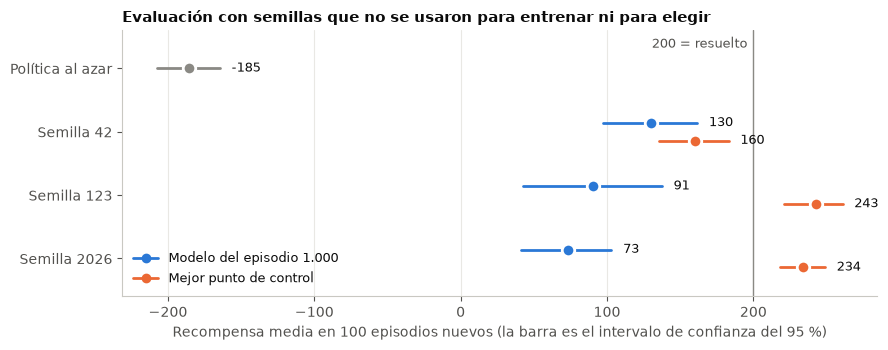

In [14]:
fig, eje = plt.subplots(figsize=(9, 3.6))
filas_y = ['Política al azar'] + [f'Semilla {s}' for s in SEMILLAS_ENTRENAMIENTO]
for nombre, fila in tabla_prueba.iterrows():
    if nombre == 'Política al azar':
        y, color, desfase = 0, GRIS, 0
    else:
        y = 1 + SEMILLAS_ENTRENAMIENTO.index(int(nombre.split()[1]))
        ultimo = 'episodio 1.000' in nombre
        color, desfase = (AZUL, -0.14) if ultimo else (NARANJA, 0.14)
    eje.plot([fila.ic95_inf, fila.ic95_sup], [y + desfase] * 2, color=color, linewidth=2)
    eje.plot(fila.media, y + desfase, 'o', color=color, markersize=9, markeredgecolor='white', markeredgewidth=2)
    eje.text(fila.ic95_sup + 8, y + desfase, f'{fila.media:.0f}', va='center', fontsize=9, color='#0b0b0b')
eje.axvline(UMBRAL, color=GRIS, linewidth=1)
eje.text(UMBRAL - 4, -0.5, '200 = resuelto', color='#52514e', fontsize=9, va='top', ha='right')
eje.set_yticks(range(4), filas_y)
eje.set_ylim(3.6, -0.6)
eje.grid(axis='y', visible=False)
eje.set_xlabel('Recompensa media en 100 episodios nuevos (la barra es el intervalo de confianza del 95 %)')
eje.plot([], [], 'o-', color=AZUL, label='Modelo del episodio 1.000')
eje.plot([], [], 'o-', color=NARANJA, label='Mejor punto de control')
eje.legend(loc='lower left', fontsize=9)
eje.set_title('Evaluación con semillas que no se usaron para entrenar ni para elegir')
fig.tight_layout()
guardar(fig, 'evaluacion_modelos.png')
plt.show()

**Lectura.**

- **La elección del mejor punto de control se sostiene con semillas nuevas.** En validación sacaban 159.2, 248.5 y 228.1; en prueba sacan 160.1, 242.6 y 234.2. No fue suerte con las semillas de validación.
- **Los modelos del episodio 1.000 quedan lejos de 200:** 130.0, 90.5 y 73.0.
- **En las tres semillas el mejor punto de control supera al último**, por 30, 152 y 161 puntos. En la semilla 42 los intervalos de confianza se cruzan, así que ahí la diferencia no es concluyente.
- **La política al azar saca −185.5** y no aterriza nunca. Todos los modelos entrenados aprendieron algo.

## 7. El agente final en detalle

El agente final es el punto de control con mejor media en validación entre las tres semillas. Se guarda en `modelos/agente_final.pth`.

In [15]:
# Agente final: el punto de control con mejor media en validación entre las tres semillas
mejores = {s: controles[s].loc[controles[s].media.idxmax()] for s in SEMILLAS_ENTRENAMIENTO}
SEMILLA_FINAL = max(mejores, key=lambda s: mejores[s].media)
EP_FINAL = int(mejores[SEMILLA_FINAL].episodio)
NOMBRE_FINAL = f'Semilla {SEMILLA_FINAL} · mejor punto (ep. {EP_FINAL})'
final = evaluaciones[NOMBRE_FINAL]
torch.save(torch.load(DIR_MODELOS / f'seed{SEMILLA_FINAL}_mejor.pth'), Path('modelos') / 'agente_final.pth')

print('Agente final:', NOMBRE_FINAL)
print(f"Validación (semillas 10000-10099): {mejores[SEMILLA_FINAL].media:.2f}, {int(mejores[SEMILLA_FINAL].ge_200)}/100 episodios con 200 o más")
r = resumir(final)
print(f"Prueba (semillas 20000-20099):     {r['media']:.2f} ± {r['desviacion']:.2f} | IC 95 % [{r['ic95_inf']:.1f}, {r['ic95_sup']:.1f}] | "
      f"mediana {r['mediana']:.1f} | mín {r['minimo']:.1f} | máx {r['maximo']:.1f} | {r['ge_200']}/100 con 200 o más")

por_desenlace = final.groupby('desenlace').agg(
    episodios=('recompensa', 'size'), recompensa_media=('recompensa', 'mean'),
    recompensa_min=('recompensa', 'min'), recompensa_max=('recompensa', 'max'), pasos_medios=('pasos', 'mean'),
    uso_motor_principal=('uso_motor_principal', 'mean'), en_plataforma=('en_plataforma', 'sum'),
    flotando=('flotando', 'sum'), fuera_de_pantalla=('fuera_de_pantalla', 'sum'))
por_desenlace['uso_motor_principal'] *= 100
por_desenlace = por_desenlace.reindex(['reposo', 'limite_tiempo', 'choque_o_fuera']).dropna(how='all')
por_desenlace.index = [NOMBRE_DESENLACE[i] for i in por_desenlace.index]
por_desenlace.to_csv(DIR_RESULTADOS / 'agente_final_por_desenlace.csv')
display(por_desenlace.round(1))

# ¿Los episodios en que la nave se sale tienen algo en común? Se mira la velocidad horizontal con la que arranca
final_vx = final.assign(grupo=np.where(final.fuera_de_pantalla, 'sale de la pantalla', 'resto'))
display(final_vx.groupby('grupo').vx_inicial.agg(['size', 'min', 'mean', 'max']).round(2))
print('Las 5 velocidades iniciales más hacia la izquierda:')
display(final.nsmallest(5, 'vx_inicial')[['semilla_evaluacion', 'vx_inicial', 'recompensa', 'desenlace', 'x_final']].round(2))

azar = evaluaciones['Política al azar']
print(f"Política al azar en las mismas semillas: {azar.recompensa.mean():.2f} ± {azar.recompensa.std(ddof=0):.2f}, "
      f"{int((azar.desenlace == 'choque_o_fuera').sum())}/100 se estrellan o salen")

Agente final: Semilla 123 · mejor punto (ep. 725)
Validación (semillas 10000-10099): 248.50, 90/100 episodios con 200 o más
Prueba (semillas 20000-20099):     242.63 ± 102.90 | IC 95 % [221.0, 260.9] | mediana 271.3 | mín -192.7 | máx 307.5 | 90/100 con 200 o más


,episodios,recompensa_media,recompensa_min,recompensa_max,pasos_medios,uso_motor_principal,en_plataforma,flotando,fuera_de_pantalla
Aterriza y queda en reposo,92,269.9,161.2,307.5,245.5,45.7,89,0,0
Llega al límite de 1.000 pasos,2,125.0,110.5,139.5,1000.0,11.8,0,0,0
Se estrella o sale de la pantalla,6,-136.9,-192.7,30.7,231.2,48.2,0,0,5


,size,min,mean,max
grupo,,,,
resto,95,-0.8,-0.08,0.65
sale de la pantalla,5,-0.8,-0.65,-0.10


Las 5 velocidades iniciales más hacia la izquierda:


,semilla_evaluacion,vx_inicial,recompensa,desenlace,x_final
52,20052,-0.80,-147.51,choque_o_fuera,-1.00
40,20040,-0.80,-162.22,choque_o_fuera,-1.01
1,20001,-0.80,307.48,reposo,-0.03
83,20083,-0.80,301.22,reposo,-0.06
80,20080,-0.79,296.13,reposo,-0.09


Política al azar en las mismas semillas: -185.45 ± 111.99, 99/100 se estrellan o salen


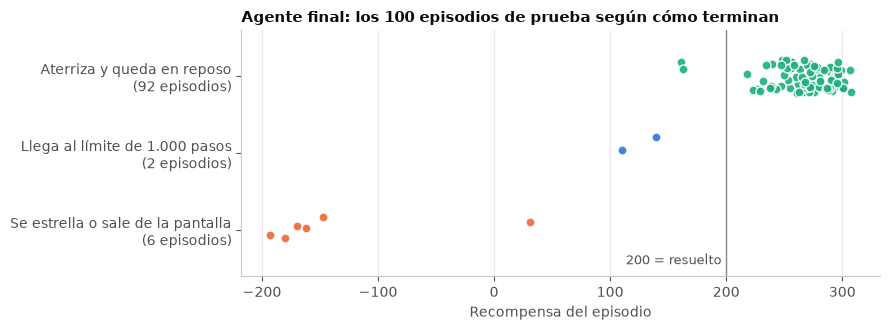

In [16]:
rng = np.random.default_rng(1)
fig, eje = plt.subplots(figsize=(9, 3.4))
etiquetas = []
for i, clave in enumerate(orden):
    datos = final[final.desenlace == clave]
    eje.scatter(datos.recompensa, i + rng.uniform(-0.22, 0.22, len(datos)), s=42, color=colores[clave],
                edgecolor='white', linewidth=1, alpha=0.9)
    etiquetas.append(f'{NOMBRE_DESENLACE[clave]}\n({len(datos)} episodios)')
eje.axvline(UMBRAL, color=GRIS, linewidth=1)
eje.text(UMBRAL - 4, 2.48, '200 = resuelto', color='#52514e', fontsize=9, ha='right', va='bottom')
eje.set_yticks(range(3), etiquetas)
eje.set_ylim(2.6, -0.6)
eje.grid(axis='y', visible=False)
eje.set_xlabel('Recompensa del episodio')
eje.set_title(f'Agente final: los 100 episodios de prueba según cómo terminan')
fig.tight_layout()
guardar(fig, 'agente_final_episodios.png')
plt.show()

**Lectura.**

- **Resultado final:** 242.63 ± 102.90 de recompensa media en 100 episodios nuevos, con un intervalo de confianza del 95 % entre 221.0 y 260.9. Supera el umbral de 200 con el que Gymnasium considera resuelto el episodio. La mediana es 271.3 y 90 de 100 episodios llegan a 200 o más.
- **Aterriza en 92 de 100 episodios**, con 269.9 de recompensa media. En 89 queda sobre la plataforma y en 3 queda quieta fuera de ella; dos de esos tres son los únicos aterrizajes por debajo de 200 (161.2 y 163.2).
- **En 2 episodios se posa pero no se queda quieta.** Sigue encendiendo los motores laterales hasta los 1.000 pasos y no recibe el +100 (110.5 y 139.5 puntos).
- **En 6 episodios pierde.** En 5 la nave se sale por el borde izquierdo de la pantalla y en 1 se estrella sobre la plataforma. Esos episodios promedian −136.9. Sin ellos la desviación estándar baja de 102.9 a 33.3.
- **Los que se salen arrancan con más impulso hacia la izquierda** (velocidad horizontal inicial media de −0.65 frente a −0.08 del resto), pero no es la única causa: otros episodios con el mismo impulso inicial aterrizan bien.
- **Usa el motor principal en el 46 % de los pasos** cuando aterriza.

## 8. Comparación con el entrenamiento en Colab

La Persona 3 entrenó en Colab con el mismo código y las mismas semillas (`Persona_3_Entrenamiento_DQN.ipynb`). Su tabla de resultados está en `resultados/persona_3/`. Aquí se compara con esta réplica; en los dos casos se trata del modelo del episodio 1.000 evaluado con las semillas de validación.

In [17]:
# Resultados de la Persona 3 en Colab: modelo del episodio 1.000, semillas de validación 10000-10099
colab = pd.read_csv('resultados/persona_3/resultados_finales_DQN_Persona3.csv', encoding='utf-8-sig').set_index('Semilla')
replica = pd.DataFrame({s: controles[s].iloc[-1] for s in SEMILLAS_ENTRENAMIENTO}).T
comparacion = pd.DataFrame({
    'colab_media': colab.Recompensa_media, 'replica_media': replica.media,
    'colab_desviacion': colab.Desviacion_estandar, 'replica_desviacion': replica.desviacion,
    'colab_mediana': colab.Mediana, 'replica_mediana': replica.mediana,
    'colab_ge_200': colab.Porcentaje_recompensa_200, 'replica_ge_200': replica.ge_200})
comparacion.index.name = 'semilla'
comparacion.to_csv(DIR_RESULTADOS / 'comparacion_colab_replica.csv')
display(comparacion.astype(float).round(2))

,colab_media,replica_media,colab_desviacion,replica_desviacion,colab_mediana,replica_mediana,colab_ge_200,replica_ge_200
semilla,,,,,,,,
42,206.39,107.07,116.31,160.32,255.41,170.96,78.0,49.0
123,205.87,116.61,104.05,209.64,254.27,242.20,74.0,62.0
2026,238.15,99.29,67.11,153.55,259.25,20.52,84.0,47.0


**Lectura.** Con el mismo código, las mismas semillas y las mismas versiones de las librerías, los resultados son distintos: 206.39, 205.87 y 238.15 en Colab frente a 107.07, 116.61 y 99.29 aquí.

La semilla fija el resultado dentro de una misma máquina (este notebook da siempre los mismos números), pero no entre máquinas. La observación inicial del ambiente ya difiere en el octavo decimal entre Colab y este computador, y esa diferencia crece durante el entrenamiento. Sumado a lo visto en la sección 5, significa que el modelo del episodio 1.000 puede caer en un punto alto o en uno bajo según la corrida.

Los pesos de los modelos entrenados en Colab quedaron fuera del repositorio, así que no se pueden evaluar con las semillas de prueba. Por eso el agente final se toma de esta réplica, cuyos modelos y resultados sí están guardados y se pueden verificar.

## 9. Conclusiones

1. **El DQN aprende a aterrizar.** Pasa de −185.5 (política al azar) a 242.6 de recompensa media en episodios nuevos, con 92 aterrizajes de 100.
2. **El resultado depende de qué modelo se guarda.** El modelo del episodio 1.000 saca entre 73.0 y 130.0 en prueba; el mejor punto de control de la misma corrida saca entre 160.1 y 242.6.
3. **La curva de entrenamiento no mide al modelo entregado.** Hay que evaluarlo congelado, sin exploración y con semillas que no se usaron para elegirlo.
4. **El aprendizaje no es estable.** Entre dos puntos de control separados por 25 episodios la recompensa media cambia hasta 188 puntos.
5. **Las semillas no bastan para reproducir el resultado en otra máquina.** Por eso se dejan guardados los modelos y los resultados en el repositorio.
6. **Límites de este análisis.** Son tres semillas de entrenamiento, 100 episodios por evaluación y una sola configuración de hiperparámetros. No se probó qué causa la inestabilidad.

## 10. Anexo: rango real de las observaciones

El espacio de observaciones declara rangos amplios (por ejemplo, velocidades entre −10 y 10). Aquí se mide qué valores aparecen de verdad, primero con acciones al azar y después con el agente final. Sirve para decidir si hace falta normalizar las entradas de la red.

In [18]:
VARIABLES = ['posición x', 'posición y', 'velocidad x', 'velocidad y', 'ángulo', 'velocidad angular',
             'contacto pata izquierda', 'contacto pata derecha']

def observaciones_visitadas(modelo, semillas):
    """Junta todas las observaciones que aparecen al jugar un episodio por semilla."""
    env = gym.make(AMBIENTE)
    vistas = []
    for semilla in semillas:
        estado, _ = env.reset(seed=int(semilla))
        env.action_space.seed(int(semilla))
        terminado = truncado = False
        vistas.append(estado)
        while not (terminado or truncado):
            if modelo is None:
                accion = int(env.action_space.sample())
            else:
                with torch.no_grad():
                    accion = int(modelo(torch.as_tensor(estado, dtype=torch.float32).unsqueeze(0)).argmax(dim=1).item())
            estado, _, terminado, truncado, _ = env.step(accion)
            vistas.append(estado)
    env.close()
    return np.array(vistas)

def tabla_rangos(obs):
    return pd.DataFrame({'mínimo': obs.min(axis=0), 'percentil 1': np.percentile(obs, 1, axis=0),
                         'percentil 99': np.percentile(obs, 99, axis=0), 'máximo': obs.max(axis=0)}, index=VARIABLES)

env = gym.make(AMBIENTE)
declarado = pd.DataFrame({'mínimo declarado': env.observation_space.low, 'máximo declarado': env.observation_space.high}, index=VARIABLES)
env.close()

al_azar = observaciones_visitadas(None, range(500))
con_agente = observaciones_visitadas(cargar(Path('modelos') / 'agente_final.pth'), SEMILLAS_PRUEBA)
rangos = pd.concat({'declarado': declarado, 'al azar (500 episodios)': tabla_rangos(al_azar),
                    'agente final (100 episodios)': tabla_rangos(con_agente)}, axis=1)
rangos.to_csv(DIR_RESULTADOS / 'rango_observaciones.csv')
print(len(al_azar), 'observaciones al azar y', len(con_agente), 'con el agente final; dtype', al_azar.dtype)
display(rangos.round(2))

46385 observaciones al azar y 26070 con el agente final; dtype float32


declarado                   \
                        mínimo declarado máximo declarado   
posición x                         -2.50             2.50   
posición y                         -2.50             2.50   
velocidad x                       -10.00            10.00   
velocidad y                       -10.00            10.00   
ángulo                             -6.28             6.28   
velocidad angular                 -10.00            10.00   
contacto pata izquierda            -0.00             1.00   
contacto pata derecha              -0.00             1.00   

                        al azar (500 episodios)                           \
                                         mínimo percentil 1 percentil 99   
posición x                                -1.02       -0.77         0.84   
posición y                                -0.39       -0.07         1.60   
velocidad x                               -1.95       -1.25         1.41   
velocidad y                               -2.12       -1.58         0.36   
ángulo                                    -3.40       -1.66         1.38   
velocidad angular                         -8.79       -1.34         1.51   
contacto pata izquierda                    0.00        0.00         1.00   
contacto pata derecha                      0.00        0.00         1.00   

                               agente final (100 episodios)              \
                        máximo                       mínimo percentil 1   
posición x                1.02                        -1.01       -0.60   
posición y                1.79                        -0.28       -0.03   
velocidad x               2.29                        -1.11       -0.76   
velocidad y               0.59                        -0.90       -0.74   
ángulo                    3.93                        -0.52       -0.42   
velocidad angular         7.29                        -1.03       -0.33   
contacto pata izquierda   1.00                         0.00        0.00   
contacto pata derecha     1.00                         0.00        0.00   

                                             
                        percentil 99 máximo  
posición x                      0.27   0.31  
posición y                      1.49   1.55  
velocidad x                     0.51   0.65  
velocidad y                     0.15   0.48  
ángulo                          0.34   0.43  
velocidad angular               0.32   1.20  
contacto pata izquierda         1.00   1.00  
contacto pata derecha           1.00   1.00

**Lectura.** En los dos casos el 98 % de los valores de cada variable queda entre −1.7 y 1.7, y las dos variables de contacto solo valen 0 o 1. Los valores extremos (por ejemplo, la velocidad angular cerca de −8.8) aparecen cuando la nave ya perdió el control. Todas las entradas tienen una escala parecida tal como las entrega el ambiente, y por eso la red las recibe sin normalizar.